# Audit Data
Mengecek kualitas dataset tangisan bayi sebelum dipakai: jumlah file per kelas, durasi, volume, duplikat, klip dari rekaman yang sama, dan shortcut. Hasilnya disimpan ke `outputs/metadata.csv`.

## 0. Setup

In [21]:

import hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.signal import correlate
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.max_columns", 30)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.dpi"] = 110

In [22]:
DATA_DIR = Path("audio")
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

SR, DUR = 16000, 6                 # 16 kHz, durasi target 6 detik
SEED = 42

CLASSES = ["burping", "needs", "physical_pain", "scared"]
LABELS = {"burping": "Perlu sendawa", "needs": "Kebutuhan umum",
          "physical_pain": "Sakit fisik", "scared": "Kaget/takut"}

# threshold audit
MIN_DUR = 0.5        # detik
SILENT_DBFS = -50.0  # RMS hening
CAND_SIM = 0.90      # cosine similarity MFCC minimum untuk jadi kandidat
CAND_K = 10          # jumlah nearest neighbor yang dicek per klip
XCORR_SAME = 0.90    # cross-correlation >= ini = potongan rekaman yang sama

## 1. Jumlah data per kelas

In [23]:
files = [(str(p), c) for c in CLASSES for p in sorted((DATA_DIR / c).glob("*.wav"))]
# hitung jumlah file per kelas
inv = pd.DataFrame(files, columns=["path", "kelas"]).kelas.value_counts().reindex(CLASSES).to_frame("jumlah_file")
inv["label"] = pd.Series(LABELS)
inv.loc["Total"] = [inv.jumlah_file.sum(), ""]
inv

,jumlah_file,label
kelas,,
burping,310,Perlu sendawa
needs,3103,Kebutuhan umum
physical_pain,774,Sakit fisik
scared,684,Kaget/takut
Total,4871,


## 2. Audit data
### 2.1 Cek tiap file
Dari setiap file diambil: sample rate, jumlah channel, durasi, bandwidth, hash isi audio, level peak dan RMS, persentase clipping, dan rata-rata 20 MFCC (dipakai untuk mencari klip yang mirip di 2.5).

In [24]:
def inspect(path, kelas):
    data, sr = sf.read(path, dtype="int16", always_2d=True)  # baca sampel mentah (int16) apa adanya
    y = data.astype(np.float32).mean(axis=1) / 32768.0  # jadikan mono, skala -1..1
    if sr != SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR)  # samakan sample rate ke 16 kHz
    peak = float(np.max(np.abs(y))) if len(y) else 0.0
    rms = float(np.sqrt(np.mean(y ** 2))) if len(y) else 0.0
    # rata-rata 20 MFCC sepanjang klip, untuk cari klip mirip
    fp = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=20).mean(axis=1) if len(y) >= 2048 else np.zeros(20)
    # bandwidth: frekuensi rolloff 99% energi
    bw = float(np.median(librosa.feature.spectral_rolloff(y=y, sr=SR, roll_percent=0.99))) if len(y) >= 2048 else 0.0
    return dict(bandwidth_hz=bw, id=Path(path).stem, path=path, kelas=kelas, sr_asli=sr, channel=data.shape[1],
                # hash dari sampel audio, bukan dari header file
                durasi=len(data) / sr, hash=hashlib.md5(data.tobytes()).hexdigest(),
                peak_dbfs=20 * np.log10(peak + 1e-12), rms_dbfs=20 * np.log10(rms + 1e-12),
                frac_clipping=float(np.mean(np.abs(y) >= 0.999)), fp=fp)  # porsi sampel yang clipping

# jalankan inspect() untuk semua file secara paralel
rows = Parallel(n_jobs=-1, verbose=1)(delayed(inspect)(p, c) for p, c in files)
df = pd.DataFrame(rows)
fps = np.stack(df.pop("fp").values)  # pisahkan vektor MFCC jadi matriks (jumlah klip x 20)
df["status"] = "lolos"
print(f"{len(df)} file diperiksa. Sample rate: {sorted(df.sr_asli.unique().tolist())}, channel: {sorted(df.channel.unique().tolist())}")
df.head()

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    3.3s
[Parallel(n_jobs=-1)]: Done 920 tasks      | elapsed:    4.8s


4871 file diperiksa. Sample rate: [16000], channel: [1]


[Parallel(n_jobs=-1)]: Done 4725 tasks      | elapsed:   10.6s
[Parallel(n_jobs=-1)]: Done 4871 out of 4871 | elapsed:   10.7s finished


,bandwidth_hz,id,path,kelas,sr_asli,channel,durasi,hash,peak_dbfs,rms_dbfs,frac_clipping,status
0,3765.62500,005d061ffd31,audio\burping\005d061ffd31.wav,burping,16000,1,6.90,6a04aa2a06e6ad85eb9772f642585836,-13.928655,-31.747184,0.0,lolos
1,3410.15625,01188ceaf2bf,audio\burping\01188ceaf2bf.wav,burping,16000,1,3.90,350329c4fd1dc4a32b65915c35bca897,-11.532602,-25.800764,0.0,lolos
2,3710.93750,01b1d21ba94e,audio\burping\01b1d21ba94e.wav,burping,16000,1,6.99,e3c2e3f6ef7d0ed47be6260f1d7084d8,-11.555632,-27.721877,0.0,lolos
3,7304.68750,02416fcef2a2,audio\burping\02416fcef2a2.wav,burping,16000,1,3.99,c646074ba1bf2697f642624c190183e8,-8.986955,-23.010659,0.0,lolos
4,3664.06250,02e3650ebc82,audio\burping\02e3650ebc82.wav,burping,16000,1,6.57,fbff6ad222447704d2ded4714beacad1,-11.199092,-26.354661,0.0,lolos


### 2.2 Durasi
Durasi yang dipakai 6 detik. Klip yang lebih pendek nanti di-padding nol, yang lebih panjang dipotong bagian tengahnya. Klip di bawah 0,5 detik dibuang.

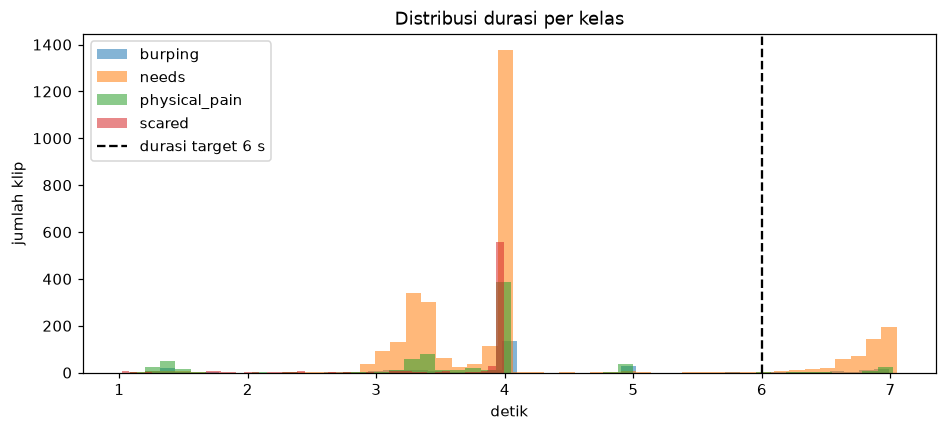

87.4% klip berdurasi <= 6 detik (di-padding); sisanya dipotong.
Klip < 0.5 s (dibuang): 0


,count,min,50%,95%,max
kelas,,,,,
burping,310.0,1.20,3.99,6.84,6.99
needs,3103.0,1.08,3.99,6.99,7.05
physical_pain,774.0,1.08,3.99,6.11,7.02
scared,684.0,1.02,3.99,3.99,3.99


In [25]:
fig, ax = plt.subplots(figsize=(10, 4))
for c in CLASSES:
    ax.hist(df[df.kelas == c].durasi, bins=50, alpha=.55, label=c)
ax.axvline(DUR, color="k", ls="--", label=f"durasi target {DUR} s")
ax.set(title="Distribusi durasi per kelas", xlabel="detik", ylabel="jumlah klip"); ax.legend()
fig.savefig(OUT / "audit_durasi.png", bbox_inches="tight"); plt.show()

df.loc[df.durasi < MIN_DUR, "status"] = "terlalu_pendek"
# statistik durasi per kelas
dur_tab = df.groupby("kelas").durasi.describe(percentiles=[.5, .95])[["count", "min", "50%", "95%", "max"]].round(2)
print(f"{100 * (df.durasi <= DUR).mean():.1f}% klip berdurasi <= {DUR} detik (di-padding); sisanya dipotong.")
print(f"Klip < {MIN_DUR} s (dibuang): {(df.durasi < MIN_DUR).sum()}")
dur_tab

### 2.3 Volume (RMS dan peak)
Klip dengan RMS di bawah -50 dBFS dianggap hening dan dibuang. Klip yang clipping hanya dicatat.

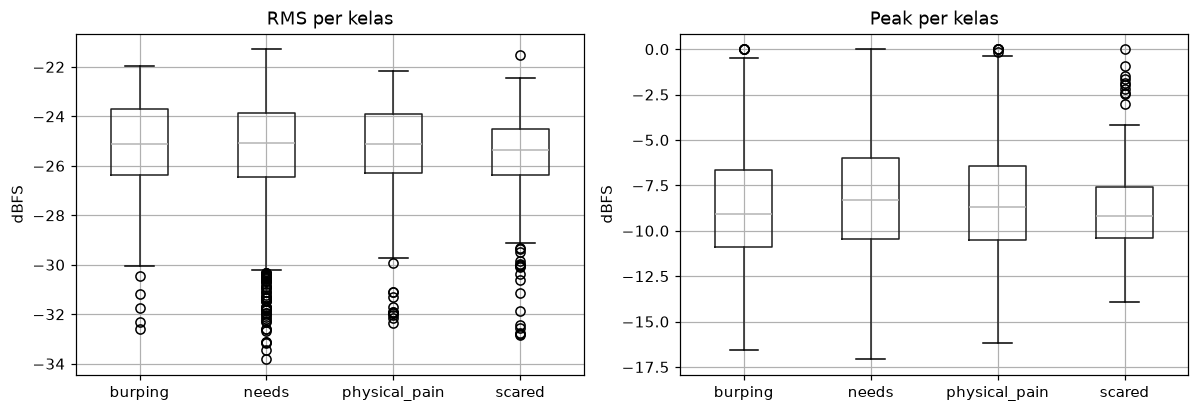

Klip hening (RMS < -50.0 dBFS, dibuang): 0
Klip dengan > 1% sampel clipping (hanya dicatat): 0


In [26]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.boxplot(column="rms_dbfs", by="kelas", ax=ax[0]); ax[0].set(title="RMS per kelas", ylabel="dBFS", xlabel="")
df.boxplot(column="peak_dbfs", by="kelas", ax=ax[1]); ax[1].set(title="Peak per kelas", ylabel="dBFS", xlabel="")
fig.suptitle(""); fig.tight_layout(); fig.savefig(OUT / "audit_level.png", bbox_inches="tight"); plt.show()

df.loc[df.rms_dbfs < SILENT_DBFS, "status"] = "hening"
print(f"Klip hening (RMS < {SILENT_DBFS} dBFS, dibuang): {(df.rms_dbfs < SILENT_DBFS).sum()}")
print(f"Klip dengan > 1% sampel clipping (hanya dicatat): {(df.frac_clipping > 0.01).sum()}")

### 2.4 Exact duplicate
File dengan hash yang sama isinya identik. Kalau kelasnya sama, cukup disimpan satu. Kalau kelasnya beda, labelnya tidak jelas jadi semuanya dibuang.

In [27]:
n_kelas = df.groupby("hash").kelas.transform("nunique")  # jumlah kelas berbeda untuk hash yang sama
# hash sama tapi kelas beda -> semua dibuang
df.loc[df.hash.duplicated(keep=False) & (n_kelas > 1), "status"] = "duplikat_konflik_label"
df.loc[df.hash.duplicated() & (n_kelas == 1), "status"] = "duplikat_persis"   # salinan pertama disimpan
print(f"Hash yang muncul lebih dari sekali: {df[df.hash.duplicated(keep=False)].hash.nunique()}")
df.status.value_counts()

Hash yang muncul lebih dari sekali: 0


status
lolos    4871
Name: count, dtype: int64

### 2.5 Near-duplicate (klip dari rekaman yang sama)
Ada klip yang tidak identik tapi sebenarnya potongan dari rekaman yang sama (hanya bergeser sedikit). Cara mencarinya:
1. cari pasangan dengan MFCC yang mirip (cosine similarity ≥ 0,90, 10 nearest neighbor),
2. cek pasangan itu dengan cross-correlation. Korelasinya dihitung di bagian yang overlap saja untuk setiap lag, jadi nilainya -1 sampai 1. Kalau nilai tertingginya ≥ 0,90, dianggap rekaman yang sama.

Klip yang saling terhubung dijadikan satu grup. Grup ini dipakai saat split data supaya potongan rekaman yang sama tidak masuk ke data train dan data test sekaligus.

Pasangan kandidat: 13569


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done 1688 tasks      | elapsed:   12.1s
[Parallel(n_jobs=-1)]: Done 11288 tasks      | elapsed:  1.0min
[Parallel(n_jobs=-1)]: Done 13569 out of 13569 | elapsed:  1.2min finished


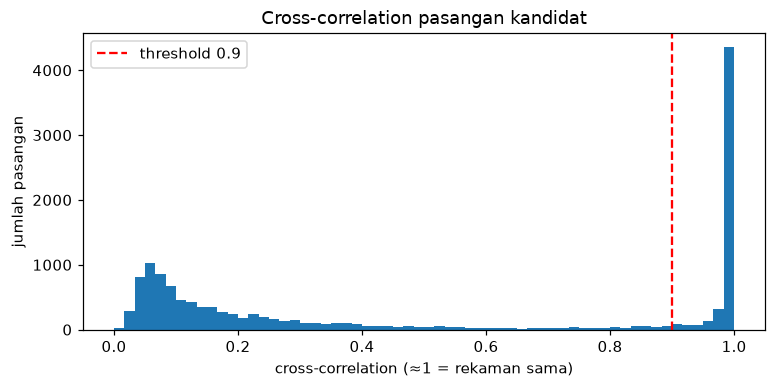

Pasangan dari rekaman yang sama: 5037
Klip dari rekaman yang sama: 3079 dari 4871 (63.2%), dalam 762 grup; grup terbesar 67 klip
Grup berisi lebih dari satu kelas (konflik label, dibuang): 170 grup, 631 klip


,file_a,kelas_a,file_b,kelas_b,similarity_mfcc,xcorr,lag_detik
6083,audio\needs\75a12c4d2dad.wav,needs,audio\physical_pain\7ca49da9499b.wav,physical_pain,0.999982,1.0,0.0
3897,audio\needs\37d21d7c3a74.wav,needs,audio\needs\471fd64dabe4.wav,needs,0.999910,1.0,0.0
11930,audio\scared\4ab28b4806ea.wav,scared,audio\scared\6d35bece4d3e.wav,scared,0.999874,1.0,0.0
545,audio\burping\65dc7817fa78.wav,burping,audio\needs\677f7eea7e31.wav,needs,0.999962,1.0,0.0
7938,audio\needs\c1454270ee74.wav,needs,audio\needs\f4e2c716779e.wav,needs,0.999756,1.0,0.0
2705,audio\needs\1db0f3ff4e9f.wav,needs,audio\physical_pain\3d0856bd2bac.wav,physical_pain,0.980428,1.0,-0.3
4615,audio\needs\4a2d84db6b0c.wav,needs,audio\physical_pain\18ba51eed1e5.wav,physical_pain,0.999711,1.0,0.0
4534,audio\needs\471fd64dabe4.wav,needs,audio\physical_pain\6e587ed4ea2c.wav,physical_pain,0.999986,1.0,0.0
4635,audio\needs\4af48d866513.wav,needs,audio\needs\f79dc19d7bb4.wav,needs,0.999907,1.0,0.0
4759,audio\needs\4dfa4b1ed149.wav,needs,audio\needs\758145394cb0.wav,needs,0.999113,1.0,0.0


In [28]:
def ncc(a, b):
    # Pearson correlation di bagian yang overlap untuk semua posisi lag, hasilnya -1 sampai 1
    la, lb = len(a), len(b)
    num = correlate(a, b, mode="full", method="fft")  # jumlah a*b untuk setiap lag
    d = np.arange(-(lb - 1), la)  # lag dalam sampel
    a0, a1 = np.maximum(d, 0), np.minimum(la, lb + d)  # bagian a yang overlap
    b0, b1 = np.maximum(0, -d), np.minimum(lb, la - d)  # bagian b yang overlap
    n = a1 - a0  # panjang overlap
    # cumsum supaya jumlah dan jumlah kuadrat tiap overlap bisa dihitung sekaligus
    ca, ca2 = np.r_[0, np.cumsum(a)], np.r_[0, np.cumsum(a * a)]
    cb, cb2 = np.r_[0, np.cumsum(b)], np.r_[0, np.cumsum(b * b)]
    sa, sa2 = ca[a1] - ca[a0], ca2[a1] - ca2[a0]
    sb, sb2 = cb[b1] - cb[b0], cb2[b1] - cb2[b0]
    r = (num - sa * sb / n) / np.sqrt(np.maximum((sa2 - sa * sa / n) * (sb2 - sb * sb / n), 1e-12))
    r[n < 0.5 * min(la, lb)] = -1  # overlap minimal 50% dari klip yang lebih pendek
    k = r.argmax()
    return float(r[k]), float(d[k] / SR)  # nilai maksimum dan lag-nya (detik)

def xcorr(pa, pb):
    a, _ = sf.read(pa, always_2d=True); b, _ = sf.read(pb, always_2d=True)
    return ncc(a.mean(1), b.mean(1))  # jadikan mono dulu

# cek: potongan dari rekaman yang sama -> ~1 (walau volumenya beda), rekaman berbeda -> ~0
t = np.random.default_rng(SEED).standard_normal(SR * 7)
r, lag = ncc(t, 0.3 * t[SR:SR * 4])
assert r > 0.999 and abs(lag - 1) < 1e-3, (r, lag)
assert ncc(t, np.random.default_rng(SEED + 1).standard_normal(SR * 4))[0] < 0.1

z = (fps - fps.mean(0)) / (fps.std(0) + 1e-9)  # normalisasi tiap koefisien MFCC
# panjang vektor jadi 1, supaya z @ z.T = cosine similarity
z /= np.linalg.norm(z, axis=1, keepdims=True) + 1e-9
sim = z @ z.T  # cosine similarity antar semua klip
np.fill_diagonal(sim, -1)  # abaikan similarity klip dengan dirinya sendiri
paths, kelas = df.path.to_numpy(dtype=object), df.kelas.to_numpy(dtype=object)
# ambil 10 nearest neighbor tiap klip yang mirip >= CAND_SIM; (i, j) diurutkan supaya pasangan tidak dobel
cand = sorted({(min(i, j), max(i, j)) for i in range(len(df))
               for j in np.argsort(-sim[i])[:CAND_K] if sim[i, j] >= CAND_SIM})
print(f"Pasangan kandidat: {len(cand)}")
# cek cross-correlation tiap pasangan kandidat
xc = Parallel(n_jobs=-1, verbose=1, batch_size=64)(delayed(xcorr)(paths[i], paths[j]) for i, j in cand)
pairs = pd.DataFrame([dict(i=i, j=j, file_a=paths[i], kelas_a=kelas[i], file_b=paths[j], kelas_b=kelas[j],
                           similarity_mfcc=sim[i, j], xcorr=c, lag_detik=g)
                      for (i, j), (c, g) in zip(cand, xc)]).sort_values("xcorr", ascending=False)
pairs.drop(columns=["i", "j"]).to_csv(OUT / "audit_pasangan_mirip.csv", index=False)

plt.figure(figsize=(8, 3.5))
plt.hist(pairs.xcorr, bins=60); plt.axvline(XCORR_SAME, color="r", ls="--", label=f"threshold {XCORR_SAME}")
plt.title("Cross-correlation pasangan kandidat"); plt.xlabel("cross-correlation (≈1 = rekaman sama)"); plt.ylabel("jumlah pasangan")
plt.legend(); plt.savefig(OUT / "audit_xcorr.png", bbox_inches="tight"); plt.show()

same = pairs[pairs.xcorr >= XCORR_SAME]  # pasangan yang dianggap rekaman sama
# graph: klip = node, pasangan rekaman sama = edge
adj = coo_matrix((np.ones(len(same)), (same.i, same.j)), shape=(len(df), len(df)))
_, df["grup"] = connected_components(adj, directed=False)  # klip yang saling terhubung = satu grup
size = df.groupby("grup").id.transform("size")  # jumlah klip di grup masing-masing
konflik = df.groupby("grup").kelas.transform("nunique") > 1  # grup yang isinya lebih dari satu kelas
df.loc[konflik & (df.status == "lolos"), "status"] = "segmen_konflik_label"

print(f"Pasangan dari rekaman yang sama: {len(same)}")
print(f"Klip dari rekaman yang sama: {(size > 1).sum()} dari {len(df)} "
      f"({100 * (size > 1).mean():.1f}%), dalam {(df.grup.value_counts() > 1).sum()} grup; grup terbesar {size.max()} klip")
print(f"Grup berisi lebih dari satu kelas (konflik label, dibuang): {df[konflik].grup.nunique()} grup, {konflik.sum()} klip")
same.drop(columns=["i", "j"]).head(10)

### 2.6 Cek shortcut
Dicek apakah kelas bisa ditebak hanya dari durasi atau bandwidth. Kalau bisa, model bisa saja belajar dari ciri itu, bukan dari suara tangisannya. Bandwidth ikut dicek karena ada klip yang frekuensi tingginya kosong (kemungkinan beda alat rekam atau sample rate asli).

Pakai decision tree kecil (max_depth 3). Sebagai pembanding, tebakan acak untuk 4 kelas sekitar 0,25 F1-macro. Kalau bandwidth jauh di atas angka itu, Mel-Spectrogram di Praproses_Data dibatasi sampai 3,5 kHz supaya semua klip punya bandwidth yang sama.

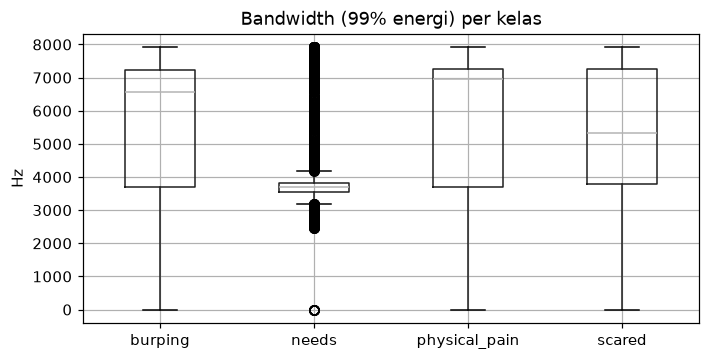

F1-Macro dari durasi saja: 0.263 ± 0.012
F1-Macro dari bandwidth saja: 0.409 ± 0.020
F1-Macro dari durasi + bandwidth saja: 0.395 ± 0.025


In [29]:
ok = df[df.status == "lolos"]
fig, ax = plt.subplots(figsize=(7, 3.5))
ok.boxplot(column="bandwidth_hz", by="kelas", ax=ax); ax.set(title="Bandwidth (99% energi) per kelas", ylabel="Hz", xlabel="")
fig.suptitle(""); fig.savefig(OUT / "audit_bandwidth.png", bbox_inches="tight"); plt.show()

shortcut = {}
for nama, kol in [("durasi", ["durasi"]), ("bandwidth", ["bandwidth_hz"]), ("durasi + bandwidth", ["durasi", "bandwidth_hz"])]:
    # decision tree kecil yang hanya melihat kolom kol, dinilai dengan 5-fold CV
    sk = cross_val_score(DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=SEED),
                         ok[kol], ok.kelas, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="f1_macro")
    shortcut[nama] = sk.mean()
    print(f"F1-Macro dari {nama} saja: {sk.mean():.3f} ± {sk.std():.3f}")

### 2.7 Ringkasan

In [30]:
df.to_csv(OUT / "metadata.csv", index=False)  # dipakai di Praproses_Data
# rekap per kelas: jumlah, lolos, dari rekaman sama, dibuang
audit_tab = df.assign(lolos=df.status == "lolos", dari_rekaman_sama=size > 1).groupby("kelas").agg(
    jumlah=("id", "size"), lolos=("lolos", "sum"), dari_rekaman_sama=("dari_rekaman_sama", "sum"))
audit_tab["dibuang"] = audit_tab.jumlah - audit_tab.lolos
audit_tab.loc["Total"] = audit_tab.sum()
print(df.status.value_counts().to_string())
audit_tab

status
lolos                   4240
segmen_konflik_label     631


,jumlah,lolos,dari_rekaman_sama,dibuang
kelas,,,,
burping,310,198,181,112
needs,3103,2799,2108,304
physical_pain,774,559,478,215
scared,684,684,312,0
Total,4871,4240,3079,631
